# 1 · Convert the raw Excel exports

Reads `data/raw/series_<n>.xlsx` and writes one CSV per sausage to `data/converted/`
(`series_<n>_sausage_<k>.csv`). Each file holds the uplinks of that sausage's two probes
(LSE01, LTC-FS) plus the shared WS202 uplinks, in arrival order: the stream the models see.

* Series 1 is annotated (column `label`: Umroetung, Reifung Phase 1, Reifung Phase 2). Series 2 is not.
* Dropped: pH probes and the ambient temperature/humidity device. They are not in the demonstrator case.
* The logic lives in `ml_core/conversion.py` (tested in `tests/test_ml_core.py`).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # project root, so ml_core is importable
import matplotlib.pyplot as plt
import pandas as pd
from ml_core import data
from ml_core.conversion import convert_all

In [2]:
RAW_DIR = data.RAW_DIR
CONVERTED_DIR = data.CONVERTED_DIR

In [3]:
summary = convert_all(RAW_DIR, CONVERTED_DIR)
summary

Reading series_1.xlsx …
  wrote series_1_sausage_1.csv (41,462 rows)
  wrote series_1_sausage_2.csv (41,479 rows)
  wrote series_1_sausage_3.csv (41,468 rows)
  wrote series_1_sausage_4.csv (41,473 rows)
  wrote series_1_sausage_5.csv (41,465 rows)
Reading series_2.xlsx …
  wrote series_2_sausage_1.csv (79,919 rows)
  wrote series_2_sausage_2.csv (79,903 rows)
  wrote series_2_sausage_3.csv (79,915 rows)
  wrote series_2_sausage_4.csv (79,920 rows)
  wrote series_2_sausage_5.csv (79,930 rows)


,file,rows,lse01 rows,ltcfs rows,ws202 rows,first,last,labeled
0,series_1_sausage_1.csv,41462,9025,9031,23406,2023-03-30 00:01:39.515132+00:00,2023-08-02 23:56:34.268438+00:00,41462
1,series_1_sausage_2.csv,41479,9034,9039,23406,2023-03-30 00:03:38.046627+00:00,2023-08-02 23:51:14.000000+00:00,41479
2,series_1_sausage_3.csv,41468,9028,9034,23406,2023-03-30 00:03:38.046627+00:00,2023-08-02 23:58:00.000000+00:00,41468
3,series_1_sausage_4.csv,41473,9034,9033,23406,2023-03-30 00:03:38.046627+00:00,2023-08-02 23:55:25.481812+00:00,41473
4,series_1_sausage_5.csv,41465,9037,9022,23406,2023-03-30 00:01:27.651646+00:00,2023-08-02 23:54:58.999977+00:00,41465
5,series_2_sausage_1.csv,79919,17579,17565,44775,2023-07-31 22:01:36.002639+00:00,2024-04-03 06:49:51.257998+00:00,0
6,series_2_sausage_2.csv,79903,17573,17555,44775,2023-07-31 22:01:36.002639+00:00,2024-04-03 06:49:51.257998+00:00,0
7,series_2_sausage_3.csv,79915,17585,17555,44775,2023-07-31 22:01:36.002639+00:00,2024-04-03 06:58:00.000000+00:00,0
8,series_2_sausage_4.csv,79920,17591,17554,44775,2023-07-31 22:01:36.002639+00:00,2024-04-03 06:51:33.172636+00:00,0
9,series_2_sausage_5.csv,79930,17592,17563,44775,2023-07-31 22:01:36.002639+00:00,2024-04-03 06:49:51.257998+00:00,0


## Sanity check: one annotated sausage over time

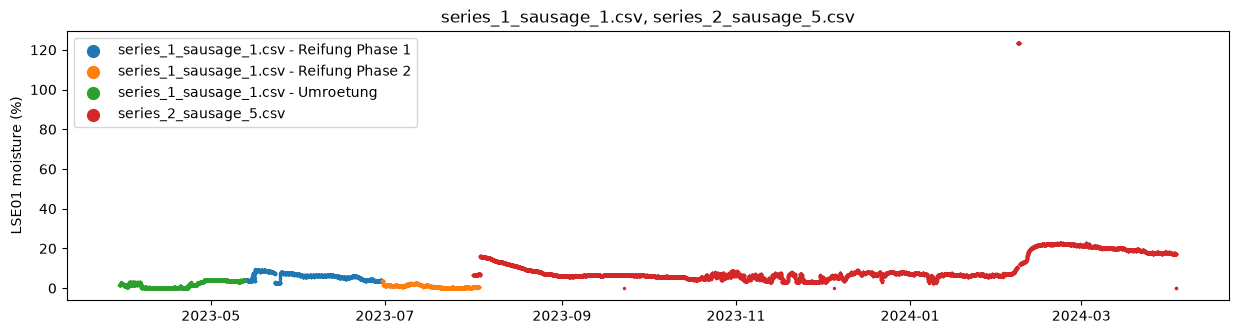

In [6]:
files = sorted(f for f in os.listdir(CONVERTED_DIR) if f.endswith(".csv"))
df_0 = pd.read_csv(os.path.join(CONVERTED_DIR, files[0]), parse_dates=["timestamp"])
df_1 = pd.read_csv(os.path.join(CONVERTED_DIR, files[-1]), parse_dates=["timestamp"])
lse_0 = df_0[df_0["sensor"] == "lse01"]
lse_1 = df_1[df_1["sensor"] == "lse01"]
fig, ax = plt.subplots(figsize=(15, 3.5))
for label, part in lse_0.groupby(lse_0.get("label", pd.Series("unlabeled", index=lse_0.index)).fillna("unlabeled")):
    ax.scatter(part["timestamp"], part["lse01_moisture"], s=2, label=f"{files[0]} - {label}")
ax.scatter(lse_1["timestamp"], lse_1["lse01_moisture"], s=2, label=f"{files[-1]}")
ax.set(title=f"{files[0]}, {files[-1]}", ylabel="LSE01 moisture (%)")
ax.legend(markerscale=6)
plt.show()